# Wettereinfluss auf den Radverkehr in Berlin
**Abschlussprojekt Data Science Weiterbildung - Analyse-Notebook**

**Fragestellung:** Wie stark beeinflussen Regen, Temperatur und Wind den Radverkehr in Berlin - und reagieren Nachtschwärmer anders auf Regen als Pendler?

**Daten (2023-2025)**
- Stündliche Zählwerte von 35 Radzählstellen der Berliner Senatsverwaltung (`gesamtdatei-stundenwerte.xlsx`)
- Stündliches Wetter der DWD-Station Berlin-Tempelhof (Niederschlag, Temperatur, Wind), abgerufen über die Bright-Sky-API
- Gesetzliche Feiertage in Berlin (Python-Modul `holidays`)

Die Daten wurden mit `main.py` extrahiert, bereinigt und in eine MariaDB-Datenbank geladen (ETL). Dieses Notebook liest sie aus der Datenbank und wertet sie aus.

**Festlegungen**
- Eine Zählstunde trägt das Label ihres Beginns: Stunde 8 = 8-9 Uhr.
- Der Wetterwert mit Zeitstempel 9:00 beschreibt die Stunde 8-9 Uhr (Niederschlag = Summe der vorangegangenen 60 Minuten). Das Wetter wird deshalb um eine Stunde versetzt zugeordnet.
- **Regenstunde:**  mindestens 0,1 mm Niederschlag.
- Fehlende oder unplausible Werte werden nicht ersetzt, sondern weggelassen.

**Hypothesen**
- **H1:** Regen und niedrige Temperaturen senken den Radverkehr.
- **H2:** Der Regeneffekt ist in Ausgehnächten schwächer als im Berufsverkehr.

**Inhalt:**  

1 - Daten laden  
2 - Erste Einblicke  
3 - Hypothese 1  
4 - Hypothese 2  
5 - Robustheit  
6 - Fazit, Grenzen und Ausblick

## 1 Daten laden
Die Funktion `abfrage()` aus `src/load/datenbank.py` verbindet sich mit der Datenbank (Zugangsdaten aus `.env`) und gibt das Ergebnis einer SQL-Abfrage als DataFrame zurück. Weil das Notebook im Ordner `notebooks/` liegt, wird der Projektordner (`..`) zum Suchpfad hinzugefügt.

In [1]:
import sys; sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt
from src.load.datenbank import abfrage

Eine Abfrage verknüpft alle vier Tabellen:
- **zaehlung** - Anzahl Räder je Zähler und Stunde; nur Werte mit Qualität `ok` oder `rekonstruiert` (unplausible Werte, Lücken und Zeitumstellungsstunden bleiben draußen)
- **zaehlstelle** - Streckentyp der Zählstelle
- **wetter** - Wetter der Folgestunde (`+ INTERVAL 1 HOUR`, siehe Festlegungen oben)
- **feiertag** - über einen LEFT JOIN wird jede Stunde als Feiertag (1) oder normaler Tag (0) markiert

In [2]:
df = abfrage("""
SELECT z.zaehlstelle_code, s.streckentyp, z.zeitpunkt, z.anzahl, z.qualitaet,
       w.niederschlag_mm, w.temperatur_c, w.wind_kmh,
       f.datum IS NOT NULL AS feiertag
FROM zaehlung z
JOIN zaehlstelle s ON s.zaehlstelle_code = z.zaehlstelle_code
JOIN wetter w ON w.zeitpunkt = z.zeitpunkt + INTERVAL 1 HOUR
LEFT JOIN feiertag f ON f.datum = DATE(z.zeitpunkt)
WHERE z.qualitaet IN ('ok','rekonstruiert')
""")
df.shape, df.anzahl.isna().sum()

((857400, 9), np.int64(0))

> **Ergebnis:** 857.400 Zählstunden mit 9 Spalten, keine fehlenden Zählwerte. In der Datenbank gibt es 857.497 gültige Zählstunden; 97 fehlen hier, weil es für 3 Stunden (jeweils am Tag der Zeitumstellung im März) keinen Wetterwert gibt und der Join sie deshalb weglässt.

### Aufbereitung
Stunden, in denen mindestens ein Wetterwert fehlt, werden entfernt. Das passiert vor dem Anlegen der Spalte `regen` - sonst würde ein fehlender Niederschlag als "trocken" gezählt. Danach werden Stunde, Wochentag (Montag = 0) und Monat aus dem Zeitstempel abgeleitet.

In [3]:
df = df.dropna(subset=["niederschlag_mm", "temperatur_c", "wind_kmh"])
df["stunde"] = df.zeitpunkt.dt.hour
df["wochentag"] = df.zeitpunkt.dt.day_of_week   # Mo = 0
df["monat"] = df.zeitpunkt.dt.month
df["regen"] = df.niederschlag_mm >= 0.1
len(df), df.regen.mean()

(851996, np.float64(0.08549453283818234))

> **Ergebnis:** 851.996 Zählstunden bleiben übrig (5.404 entfernt, das entspricht rund 170 Stunden mit Lücken in den Wetterdaten). In 8,6 % der Zählstunden hat es geregnet.

## 2 Erste Einblicke
### 2.1 Tagesverlauf an Werktagen
Durchschnittliche Zahl der Räder pro Stunde und Zähler.  
Montag bis Freitag ohne Feiertage, getrennt nach trockenen Stunden und Regenstunden.

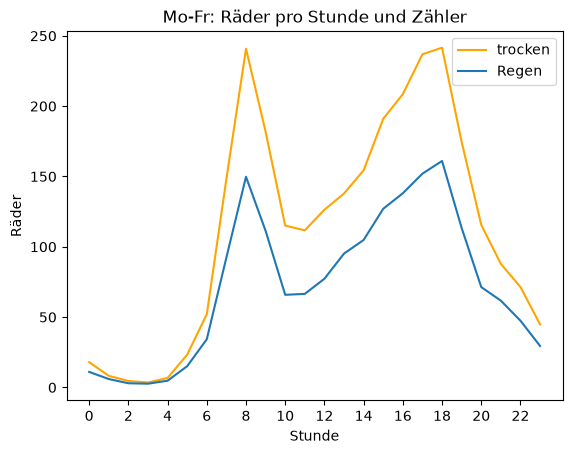

In [4]:
t = df[(df.wochentag < 5) & (df.feiertag == 0)]
t.groupby(["stunde", "regen"]).anzahl.mean().unstack().rename(columns={False: "trocken", True: "Regen"}).plot(title="Mo-Fr: Räder pro Stunde und Zähler", xlabel="Stunde", ylabel="Räder", xticks=range(0,24,2), color=["orange", "tab:blue"])
plt.legend(title=None)
plt.show()

> **Ergebnis:** Der Radverkehr an Werktagen hat zwei deutliche Spitzen, morgens gegen 8 Uhr und nachmittags gegen 17 Uhr. Klares Muster des Pendelverkehrs erkennbar. Bei Regen liegt die Kurve zu jeder Tageszeit niedriger. Dieser einfache Vergleich berücksichtigt aber noch nicht, dass Regen je nach Jahreszeit unterschiedlich häufig ist.

### 2.2 Radverkehr und Temperatur
Nur Werktage zwischen 7 und 20 Uhr ohne Regen, damit sich der Temperatureffekt nicht mit Nachtstunden oder Regen vermischt. Die Temperatur ist in 5-Grad-Klassen eingeteilt ("10 bis 15" = mindestens 10 °C und unter 15 °C).

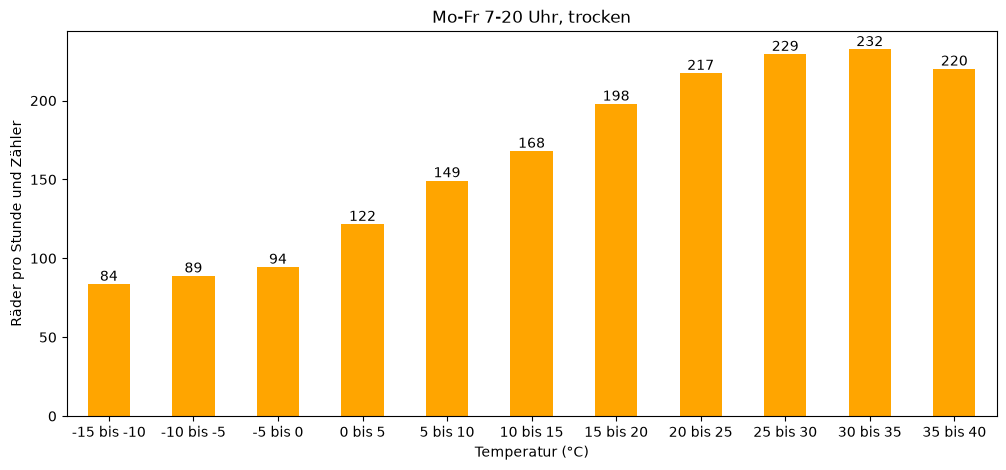

-15 bis -10     83.7
-10 bis -5      88.9
-5 bis 0        94.5
0 bis 5        121.7
5 bis 10       149.3
10 bis 15      168.0
15 bis 20      197.9
20 bis 25      217.4
25 bis 30      229.4
30 bis 35      232.4
35 bis 40      220.1
Name: anzahl, dtype: float64

In [5]:
tag = t[t.stunde.between(7, 19) & ~t.regen]
s = tag.groupby(tag.temperatur_c // 5 * 5).anzahl.mean()
s.index = [f"{k:.0f} bis {k + 5:.0f}" for k in s.index]
s.plot(kind="bar", rot=0, figsize=(12, 5), color="orange", title="Mo-Fr 7-20 Uhr, trocken", xlabel="Temperatur (°C)", ylabel="Räder pro Stunde und Zähler")  
plt.bar_label(plt.gca().containers[0], fmt="%.0f")  
plt.show()  
s.round(1)

> **Ergebnis:**  Unter 0 °C bleibt der Radverkehr fast gleich niedrig, bei 84 bis 95 Rädern pro Stunde und Zähler. Ab 0 °C steigt er deutlich. Bei 25 bis 35 °C sind es mit rund 230 Rädern mehr als doppelt so viele, über 35 °C sinkt der Wert leicht auf 220. Die äußersten Klassen sind wenig verlässlich: Unter -10 °C stehen nur 33 Zählstunden dahinter, über 35 °C nur 231, in den mittleren Klassen dagegen 40.000 bis 55.000.

## 3 Hypothese 1: Regen und Kälte senken den Radverkehr
**Methode:** lineare Regression (OLS, `statsmodels`) mit allen Zählstellen.
- **Zielgröße** ist `log(Anzahl + 1)`. Durch den Logarithmus lassen sich die Effekte als Prozent lesen, und ein Regenschauer nachts (wenige Räder) wird mit einem Schauer morgens (viele Räder) vergleichbar. "+1", weil es Stunden mit 0 Rädern gibt.
- **Erklärende Größen:** Regen (ja/nein), Temperatur, Wind, Feiertag.
- **Kontrollgrößen** als Kategorien `C(...)`: Stunde, Wochentag, Monat, Zählstelle. Damit wird z.B. eine Regenstunde dienstags um 8 Uhr im März an der Oberbaumbrücke mit einer trockenen Stunde unter denselben Bedingungen verglichen.
- Die Koeffizienten werden mit `exp(b) - 1` in Prozent umgerechnet.

In [6]:
import numpy as np
import statsmodels.formula.api as smf
m = smf.ols("np.log1p(anzahl) ~ regen + temperatur_c + wind_kmh + feiertag + C(stunde) + C(wochentag) + C(monat) + C(zaehlstelle_code)", data=df).fit()
print(m.rsquared)
np.expm1(m.params[["regen[T.True]", "temperatur_c", "wind_kmh", "feiertag"]]) * 100

0.8374771139864068


regen[T.True]   -28.824096
temperatur_c      2.934106
wind_kmh         -0.595912
feiertag        -47.779428
dtype: float64

> **Ergebnis: H1 bestätigt.**

| Einflussgröße | Effekt auf den Radverkehr |
|---|---|
| Regen (≥ 0,1 mm) | **-28,8 %** |
| Temperatur | **+2,9 % pro °C** (10 °C wärmer ca. +33 %) |
| Wind | **-0,6 % pro km/h** (20 km/h mehr ca. -11 %) |
| Feiertag | **-47,8 %** |

Das Modell erklärt 84 % der Schwankung (R² = 0,84); den größten Teil davon erklären Uhrzeit und Zählstelle. Der rohe Unterschied zwischen Regen- und Trockenstunden liegt bei −36 % (Prüfabfrage in `sql/pruefung.sql`), mit Kontrollen sind es -29 %. Ein Teil des rohen Unterschieds entsteht also, weil es öfter zu Zeiten regnet, in denen sowieso weniger gefahren wird.

Hinweis: Die Standardfehler dieses Modells sind zu klein, weil alle Zählstellen dasselbe Wetter haben und aufeinanderfolgende Stunden zusammenhängen. Interpretiert werden deshalb nur die Effektgrößen.

## 4 Hypothese 2: Reagieren Nachtschwärmer anders auf Regen als Pendler?
**Orte:** Vier Zählstellen, Ost- und Westrichtung jeweils summiert. Eine Stunde zählt nur, wenn alle Richtungen eines Orts einen gültigen Wert haben.
- **Ausgehstrecken:** Oberbaumbrücke, Maybachufer - nachts am Wochenende rund 2,5-mal so viel Verkehr wie in Werktagsnächten
- **Pendlerstrecken:** Karl-Marx-Allee, Invalidenstraße - Faktor nur rund 1,7, dafür starker Berufsverkehr

**Zeitfenster**
- **Berufsverkehr:** Mo-Fr, 7-9 Uhr, ohne Feiertage
- **Ausgehnacht:** Sa und So, 0-5 Uhr (Nächte Fr->Sa und Sa->So)
- **Werktagsnacht (Vergleich):** Di-Fr, 0-5 Uhr; die Nacht So->Mo ist ausgeschlossen, weil sie gemischt ist

### 4.1 Übersicht: Mittelwerte trocken und bei Regen

In [7]:
ort = {"05-FK-OBB-O": "Oberbaumbrücke", "05-FK-OBB-W": "Oberbaumbrücke", "21-NK-MAY": "Maybachufer",
       "01-MI-AL-W": "Karl-Marx-Allee", "03-MI-SAN-O": "Invalidenstraße", "03-MI-SAN-W": "Invalidenstraße"}
h = df[df.zaehlstelle_code.isin(ort)].copy()
h["ort"] = h.zaehlstelle_code.map(ort)
g = h.groupby(["ort", "zeitpunkt", "stunde", "wochentag", "feiertag", "regen"]).anzahl.agg(["sum", "size"]).reset_index()
g = g[g["size"] == g.groupby("ort")["size"].transform("max")]
g["fenster"] = ""
g.loc[(g.wochentag < 5) & g.stunde.isin([7, 8]) & (g.feiertag == 0), "fenster"] = "Berufsverkehr"
g.loc[(g.wochentag >= 5) & (g.stunde <= 4), "fenster"] = "Ausgehnacht"
g.loc[g.wochentag.between(1, 4) & (g.stunde <= 4), "fenster"] = "Werktagsnacht"
w = g[g.fenster != ""]
e = w.groupby(["fenster", "ort", "regen"])["sum"].mean().unstack()
e["effekt_%"] = (e[True] / e[False] - 1) * 100
e["regenstunden"] = w.groupby(["fenster", "ort"]).regen.sum()
e.round(1).rename(columns={False: "trocken", True: "Regen"})

regen                          trocken  Regen  effekt_%  regenstunden
fenster       ort                                                    
Ausgehnacht   Invalidenstraße     29.7   17.2     -42.2           136
              Karl-Marx-Allee     17.7    8.7     -51.1           136
              Maybachufer         45.1   28.9     -36.0           136
              Oberbaumbrücke     154.2   86.2     -44.1           136
Berufsverkehr Invalidenstraße    387.8  248.3     -36.0           144
              Karl-Marx-Allee    449.6  256.8     -42.9           144
              Maybachufer        314.7  229.7     -27.0           144
              Oberbaumbrücke     655.3  444.1     -32.2           144
Werktagsnacht Invalidenstraße     17.2   11.5     -32.8           227
              Karl-Marx-Allee      9.9    5.8     -40.9           227
              Maybachufer         17.1   11.3     -34.0           227
              Oberbaumbrücke      60.7   36.9     -39.3           227

> **Ergebnis:** In dieser einfachen Übersicht ist der Regeneffekt in der Ausgehnacht an allen vier Orten **stärker** als im Berufsverkehr (z.B. Oberbaumbrücke -44 % gegenüber -32 %, Maybachufer -36 % gegenüber -27 %). Außerdem reagieren die Ausgehstrecken in jedem Zeitfenster schwächer auf Regen als die Pendlerstrecken; die Karl-Marx-Allee reagiert immer am stärksten.
>
> Die Zahl der Regenstunden ist je Fenster an allen Orten gleich (Ausgehnacht 136, Berufsverkehr 144, Werktagsnacht 227), weil alle Orte dieselbe Wetterstation haben. Saison und Temperatur sind hier noch nicht berücksichtigt - deshalb folgt ein kontrollierter Vergleich.

### 4.2 Kontrollierter Vergleich
Für jedes Zeitfenster wird eine eigene Regression gerechnet, kontrolliert für Temperatur, Wind, Monat, Ort, Stunde und Wochentag.

Die Standardfehler werden nach Tag geclustert: Alle vier Orte haben dasselbe Wetter, und die Stunden einer Nacht hängen zusammen. Ohne Clusterung wären die Konfidenzintervalle zu schmal. Das **95-%-Konfidenzintervall** (KI) gibt den Bereich an, in dem der wahre Effekt mit hoher Wahrscheinlichkeit liegt.

In [8]:
w2 = w.rename(columns={"sum": "anzahl"}).merge(df.drop_duplicates("zeitpunkt")[["zeitpunkt", "temperatur_c", "wind_kmh", "monat"]], on="zeitpunkt")
erg = []
for fen in ["Berufsverkehr", "Ausgehnacht", "Werktagsnacht"]:
    d = w2[w2.fenster == fen]
    m2 = smf.ols("np.log1p(anzahl) ~ regen + temperatur_c + wind_kmh + C(monat) + C(ort) + C(stunde) + C(wochentag)", data=d).fit(cov_type="cluster", cov_kwds={"groups": d.zeitpunkt.dt.normalize().astype("int64")})
    ki = np.expm1(m2.conf_int().loc["regen[T.True]"]) * 100
    erg.append([fen, np.expm1(m2.params["regen[T.True]"]) * 100, ki.iloc[0], ki.iloc[1]])
pd.DataFrame(erg, columns=["Zeitfenster", "Regeneffekt %", "KI unten", "KI oben"]).round(1)

,Zeitfenster,Regeneffekt %,KI unten,KI oben
0,Berufsverkehr,-30.3,-35.7,-24.4
1,Ausgehnacht,-33.4,-41.3,-24.5
2,Werktagsnacht,-21.1,-26.0,-15.9


> **Ergebnis: H2 nicht bestätigt.**

| Zeitfenster | Regeneffekt | 95-%-KI |
|---|---|---|
| Berufsverkehr | **-30,3 %** | -35,7 bis -24,4 % |
| Ausgehnacht | **-33,4 %** | -41,3 bis -24,5 % |
| Werktagsnacht | **-21,1 %** | -26,0 bis -15,9 % |

Mit Kontrollen sind Ausgehnacht und Berufsverkehr praktisch gleich stark vom Regen betroffen; die Konfidenzintervalle überlappen fast vollständig. Der stärkere Nacht-Effekt aus der Übersicht geht also vor allem auf Saison und Temperatur zurück: Nächtlicher Regen fällt eher in Zeiten, in denen nachts ohnehin wenig gefahren wird.

Werktagsnächte reagieren am schwächsten. Eine mögliche Erklärung: Wer unter der Woche nachts fährt, muss häufig fahren (z.B. Schichtarbeit). Die Intervalle überschneiden sich aber knapp, der Unterschied ist daher nicht gesichert.

## 5 Robustheit
Das H1-Modell wird mit geänderten Annahmen wiederholt, um zu prüfen, ob der Regeneffekt stabil bleibt:
- **Regen ab 0,5 mm** statt 0,1 mm - zählt nur spürbaren Regen
- **ohne rekonstruierte Zählwerte** - nur Originalmessungen
- **mit Regen der Vorstunde** als zusätzliche Größe - wirkt Regen nach, z.B. durch nasse Straßen?

In [9]:
f = "np.log1p(anzahl) ~ regen + temperatur_c + wind_kmh + feiertag + C(stunde) + C(wochentag) + C(monat) + C(zaehlstelle_code)"
r = df.drop_duplicates("zeitpunkt").set_index("zeitpunkt").regen
df["regen_vor"] = (df.zeitpunkt - pd.Timedelta(hours=1)).map(r).astype(float)
varianten = {"Regen ab 0,5 mm": (f, df.assign(regen=df.niederschlag_mm >= 0.5)),
             "ohne rekonstruiert": (f, df[df.qualitaet == "ok"]),
             "mit Regen Vorstunde": (f + " + regen_vor", df)}
erg = [["Basis (H1)", np.expm1(m.params["regen[T.True]"]) * 100, np.nan]]
for n, (formel, d) in varianten.items():
    p = smf.ols(formel, data=d).fit().params
    erg.append([n, np.expm1(p["regen[T.True]"]) * 100, np.expm1(p.get("regen_vor", np.nan)) * 100])
pd.DataFrame(erg, columns=["Variante", "Regen %", "Regen Vorstunde %"]).round(1)

,Variante,Regen %,Regen Vorstunde %
0,Basis (H1),-28.8,NaN
1,"Regen ab 0,5 mm",-33.7,NaN
2,ohne rekonstruiert,-28.9,NaN
3,mit Regen Vorstunde,-19.2,-19.9


> **Ergebnis: Der Regeneffekt ist robust.**

| Variante | Regen | Regen in der Vorstunde |
|---|---|---|
| Basis (H1) | -28,8 % |  |
| Regen ab 0,5 mm | -33,7 % | - |
| ohne rekonstruierte Werte | -28,9 % | - |
| mit Regen der Vorstunde | -19,2 % | -19,9 % |

- Spürbarer Regen (ab 0,5 mm) senkt den Radverkehr stärker - plausibel.
- Rekonstruierte Werte verändern das Ergebnis praktisch nicht.
- **Regen wirkt nach:** Auch in der Stunde nach einem Schauer fahren rund 20 % weniger. Regnet es in beiden Stunden, ergibt sich zusammen etwa -35 %. Der Basiswert von -29 % enthält also einen Teil dieses Nachwirkens.

## 6 Fazit, Grenzen und Ausblick
### Fazit
- **H1 bestätigt:** Regen senkt den Radverkehr in Berlin um rund 29 % (spürbarer Regen um 34 %), und der Effekt hält in der Folgestunde an. Je Grad wärmer fahren 2,9 % mehr, Wind senkt den Radverkehr leicht.
- **H2 nicht bestätigt:** Nachtschwärmer reagieren genauso stark auf Regen wie Pendler (-33 % gegenüber -30 %). Am wenigsten lassen sich Radfahrende in Werktagsnächten abschrecken.
- Ausgehstrecken reagieren in der einfachen Übersicht schwächer auf Regen als Pendlerstrecken

### Grenzen
- Eine Wetterstation (Tempelhof) für ganz Berlin; lokaler Regen an den 3-7 km entfernten Zählstellen kann abweichen.
- Die Standardfehler in H1 sind ohne Clusterung zu klein, deshalb werden dort nur Effektgrößen interpretiert; H2 ist mit Clusterung nach Tag gerechnet.
- H2 beruht auf vier Orten und nur 136-227 Regenstunden je Zeitfenster.
- Zählstellen zählen Räder, nicht Personen oder Wege. Ob Radfahrende bei Regen auf Bus und Bahn umsteigen oder zu Hause bleiben, zeigen die Daten nicht.
- Beobachtungsdaten: Die Ergebnisse beschreiben Zusammenhänge, keine streng kausalen Effekte.

### Ausblick
- Lokaler Niederschlag aus dem neuen DWD-Messnetz in Berlin (ab 2024) statt einer einzigen Station
- Vergleich mit der Zeit vor Corona (2017-2019)
- Unterschiede zwischen Zählstellen genauer untersuchen (z.B. Regeneffekt je Zählstelle)